Training classifiers and computing error curves...
  SVM (RBF)               ->  test accuracy = 0.9533
  Logistic Regression     ->  test accuracy = 0.9233
  Random Forest           ->  test accuracy = 0.9533
  XGBoost                 ->  test accuracy = 0.9500
  MLP                     ->  test accuracy = 0.9600


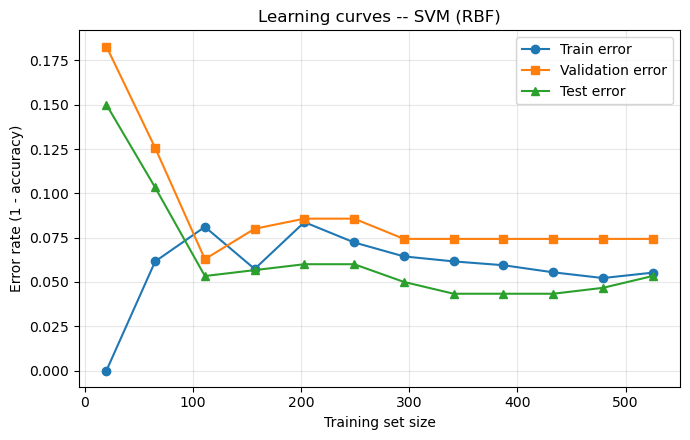

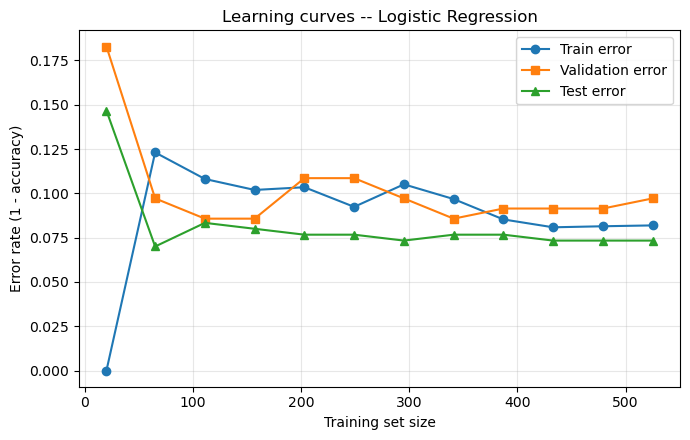

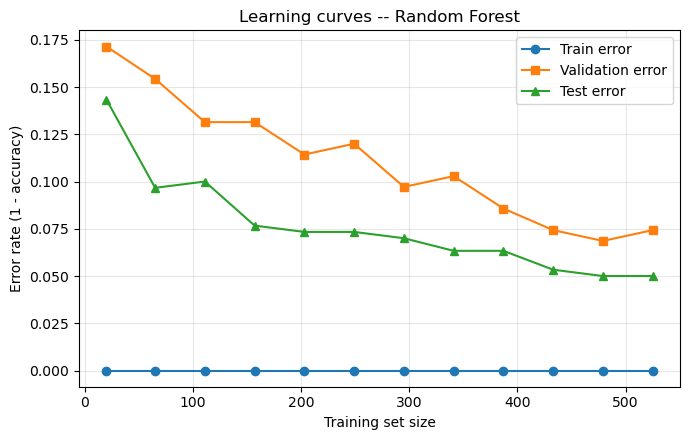

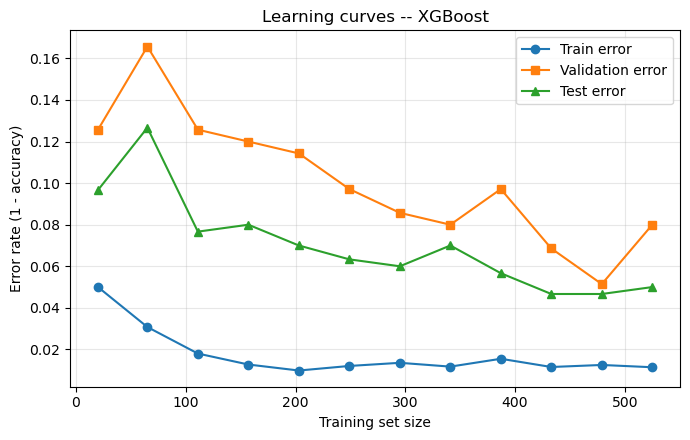

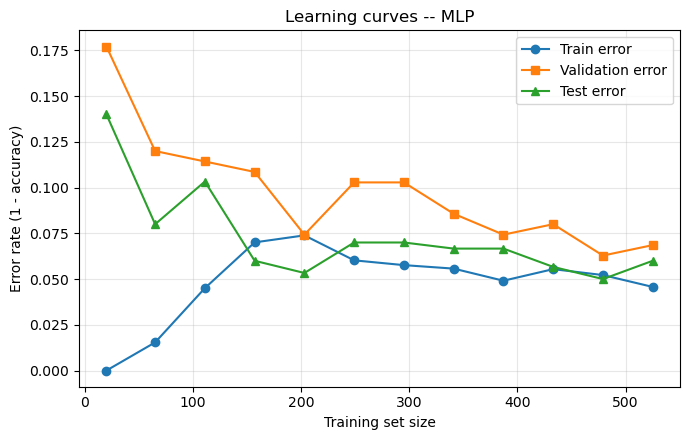

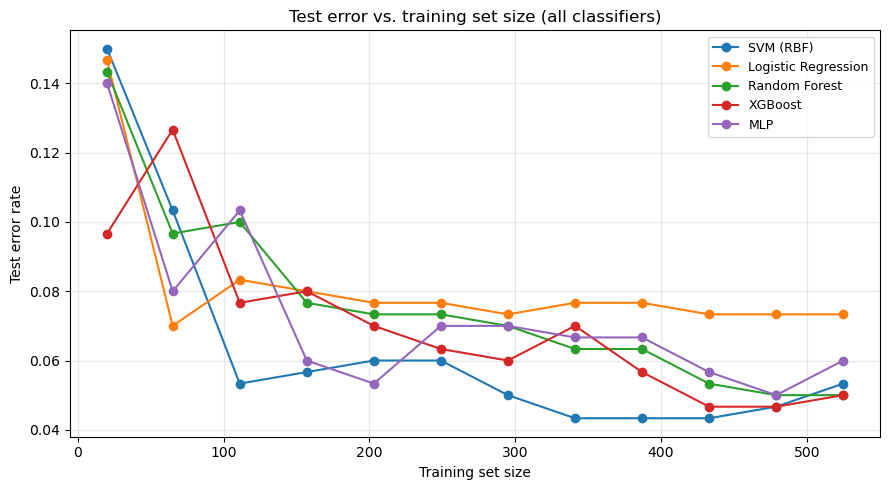

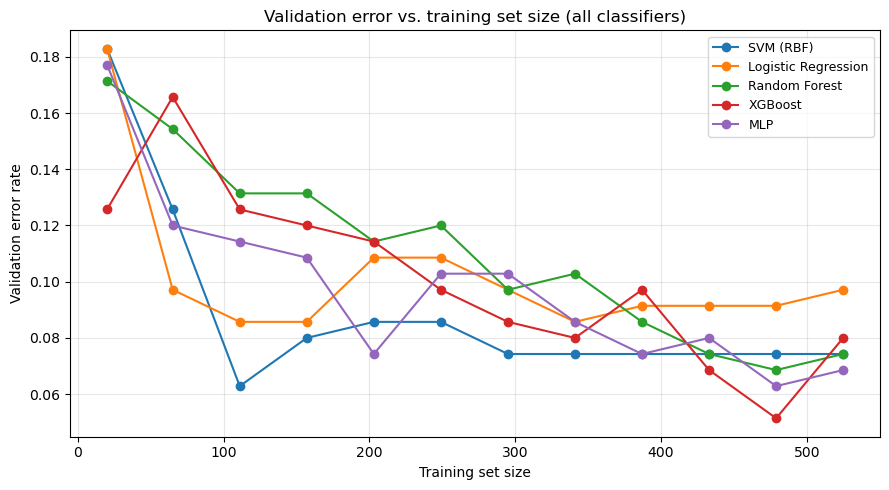

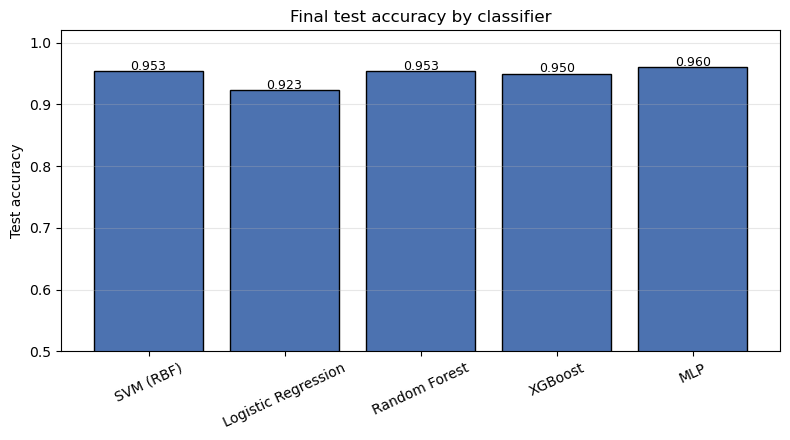

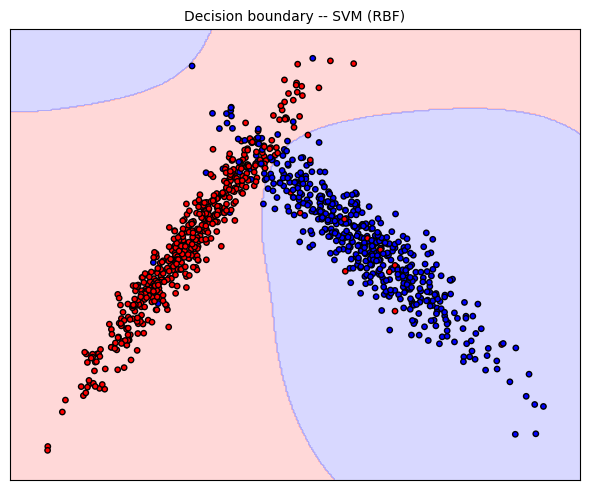

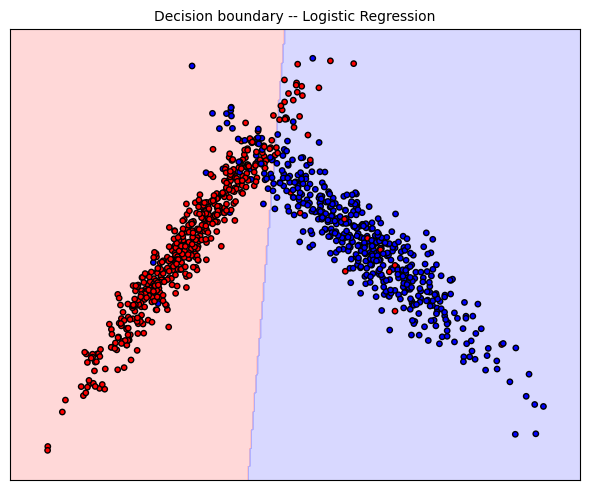

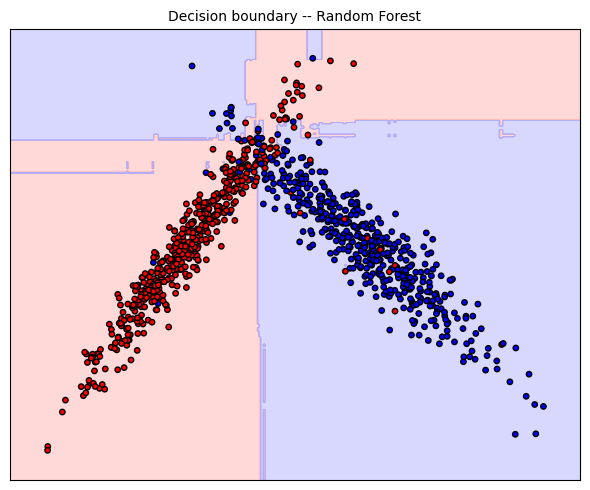

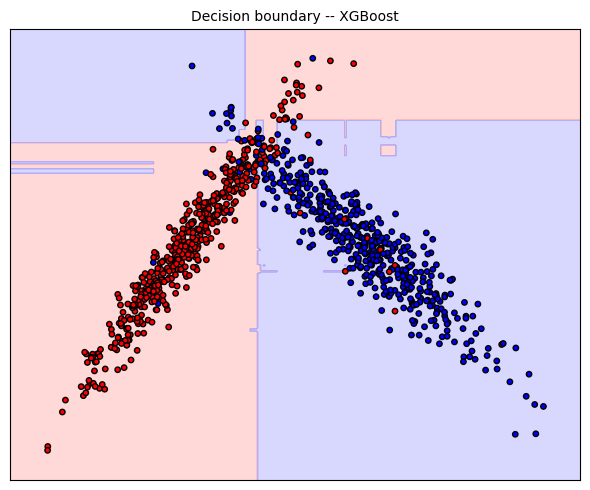

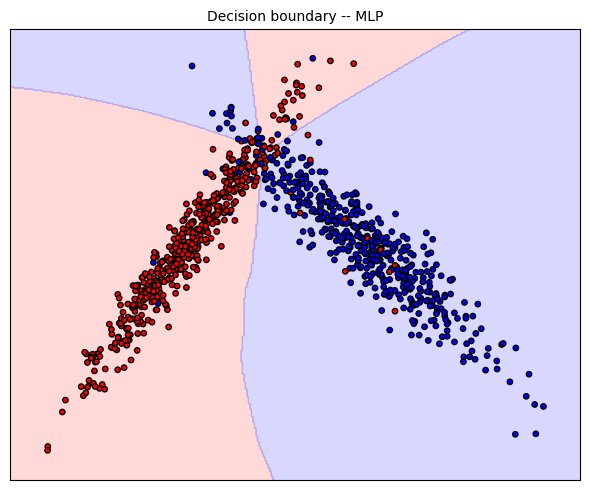

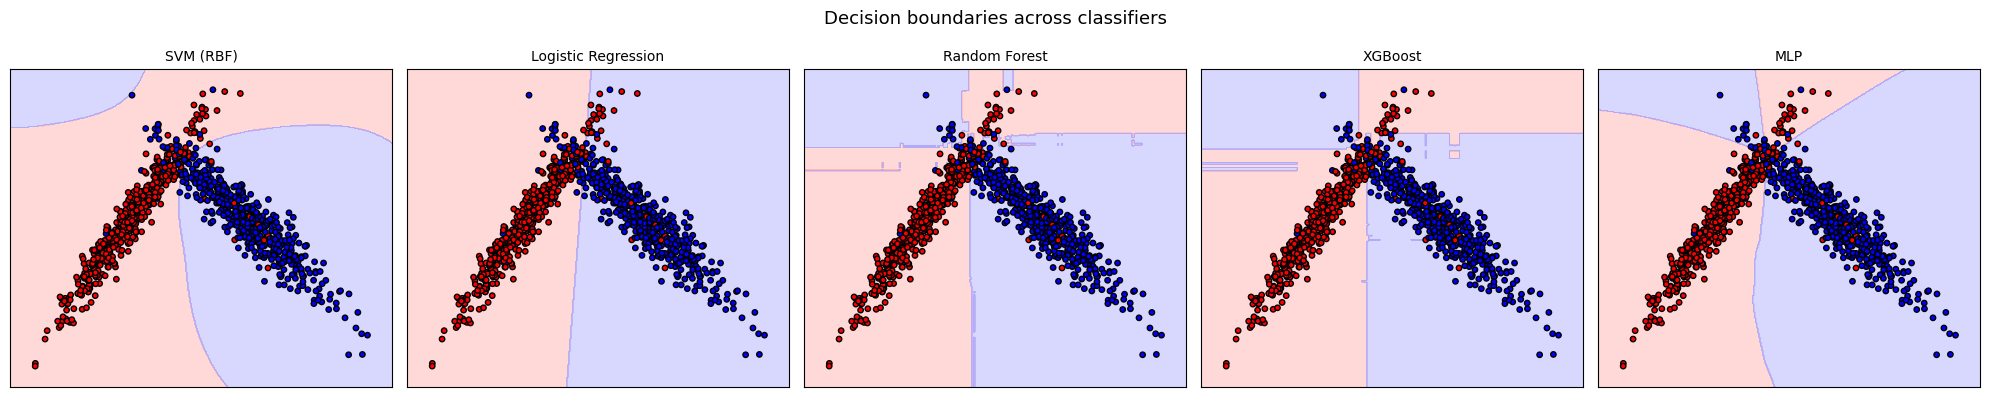


Done. All classifiers have been evaluated.


In [1]:
# =============================================================================
# Binary Classifier Comparison Toolkit
# =============================================================================
# This script compares SVM, Logistic Regression, Random Forest, XGBoost, 
# and MLP classifiers on an approximately separable synthetic dataset.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# =============================================================================
# 1. Dataset generation (approximately separable)
# =============================================================================
# We create a 2D dataset with some overlap so that classifiers don't all
# achieve 100% accuracy -- making their differences visible.
X, y = make_classification(
    n_samples=1000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.2,      # moderate separation -> "approximately separable"
    flip_y=0.05,        # 5% label noise
    random_state=42
)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# =============================================================================
# 2. Classifiers dictionary
# =============================================================================
classifiers = {
    'SVM (RBF)': make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
    ),
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=None, random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        use_label_encoder=False, eval_metric='logloss',
        random_state=42, n_jobs=-1
    ),
    'MLP': make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500,
                      random_state=42, early_stopping=False)
    ),
}

# =============================================================================
# 3. Helper: compute train / validation / test error curves
# =============================================================================
def compute_error_curves(clf, X_tr, y_tr, X_val, y_val, X_te, y_te,
                         n_points=12, min_size=20):
    """Train the classifier on increasing subsets and record errors."""
    n = len(X_tr)
    sizes = np.unique(np.linspace(min_size, n, n_points).astype(int))
    train_err, val_err, test_err = [], [], []

    for s in sizes:
        clf.fit(X_tr[:s], y_tr[:s])
        train_err.append(1 - accuracy_score(y_tr[:s], clf.predict(X_tr[:s])))
        val_err.append(1 - accuracy_score(y_val, clf.predict(X_val)))
        test_err.append(1 - accuracy_score(y_te, clf.predict(X_te)))
    return sizes, np.array(train_err), np.array(val_err), np.array(test_err)

# =============================================================================
# 4. Fit each classifier, collect results
# =============================================================================
# Split training set into train / validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

results = {}

print("=" * 70)
print("Training classifiers and computing error curves...")
print("=" * 70)

for name, clf in classifiers.items():
    sizes, tr_err, val_err, te_err = compute_error_curves(
        clf, X_train, y_train, X_val, y_val, X_test, y_test
    )
    results[name] = dict(sizes=sizes, train=tr_err, val=val_err, test=te_err)

    # Final fit on full training data for the boundary plot
    clf.fit(X_train_full, y_train_full)
    acc_test = accuracy_score(y_test, clf.predict(X_test))
    print(f"  {name:22s}  ->  test accuracy = {acc_test:.4f}")

# =============================================================================
# 5. Per-classifier learning curves (train / validation / test error)
# =============================================================================
for name, r in results.items():
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(r['sizes'], r['train'], 'o-', label='Train error', color='#1f77b4')
    ax.plot(r['sizes'], r['val'],   's-', label='Validation error', color='#ff7f0e')
    ax.plot(r['sizes'], r['test'],  '^-', label='Test error', color='#2ca02c')
    ax.set_xlabel('Training set size')
    ax.set_ylabel('Error rate (1 - accuracy)')
    ax.set_title(f'Learning curves -- {name}')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 6. Summary plot: test error curves for all classifiers
# =============================================================================
fig, ax = plt.subplots(figsize=(9, 5))
for name, r in results.items():
    ax.plot(r['sizes'], r['test'], 'o-', label=name)
ax.set_xlabel('Training set size')
ax.set_ylabel('Test error rate')
ax.set_title('Test error vs. training set size (all classifiers)')
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Validation error summary
fig, ax = plt.subplots(figsize=(9, 5))
for name, r in results.items():
    ax.plot(r['sizes'], r['val'], 'o-', label=name)
ax.set_xlabel('Training set size')
ax.set_ylabel('Validation error rate')
ax.set_title('Validation error vs. training set size (all classifiers)')
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =============================================================================
# 7. Bar plot of final test accuracies
# =============================================================================
final_acc = {}
for name, clf in classifiers.items():
    clf.fit(X_train_full, y_train_full)
    final_acc[name] = accuracy_score(y_test, clf.predict(X_test))

fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(final_acc.keys())
values = [final_acc[n] for n in names]
bars = ax.bar(names, values, color='#4c72b0', edgecolor='black')
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.002,
            f'{v:.3f}', ha='center', fontsize=9)
ax.set_ylim(0.5, 1.02)
ax.set_ylabel('Test accuracy')
ax.set_title('Final test accuracy by classifier')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# =============================================================================
# 8. Decision-boundary plots (per classifier)
# =============================================================================
def plot_decision_boundary(clf, X, y, title, ax, h=0.02):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    cmap_bg = ListedColormap(['#FFAAAA', '#AAAAFF'])
    cmap_pt = ListedColormap(['#FF0000', '#0000FF'])
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.45)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_pt, edgecolor='k', s=15)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(())
    ax.set_yticks(())

# Individual boundary plots
for name, clf in classifiers.items():
    clf.fit(X_train_full, y_train_full)
    fig, ax = plt.subplots(figsize=(6, 5))
    plot_decision_boundary(clf, X, y, f'Decision boundary -- {name}', ax)
    plt.tight_layout()
    plt.show()

# Combined boundary panel
fig, axes = plt.subplots(1, len(classifiers), figsize=(4 * len(classifiers), 4))
for ax, (name, clf) in zip(axes, classifiers.items()):
    clf.fit(X_train_full, y_train_full)
    plot_decision_boundary(clf, X, y, name, ax)
plt.suptitle('Decision boundaries across classifiers', fontsize=13)
plt.tight_layout()
plt.show()

print("\nDone. All classifiers have been evaluated.")


DATASET: Moons   |   n = 1000, features = 2
  SVM (RBF)               ->  test accuracy = 0.9400
  Logistic Regression     ->  test accuracy = 0.8833
  Random Forest           ->  test accuracy = 0.9400
  XGBoost                 ->  test accuracy = 0.9200
  MLP                     ->  test accuracy = 0.9233


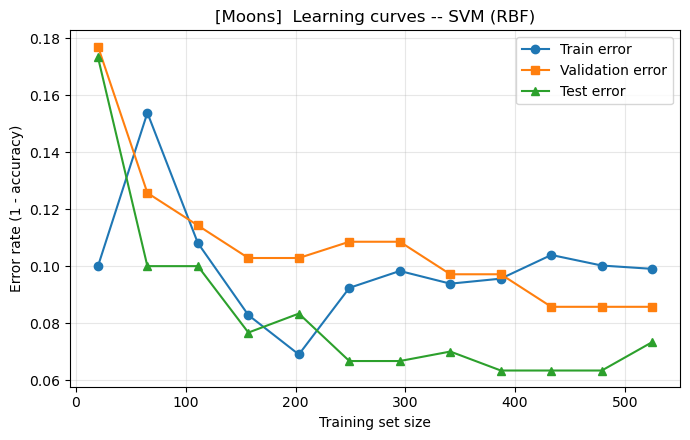

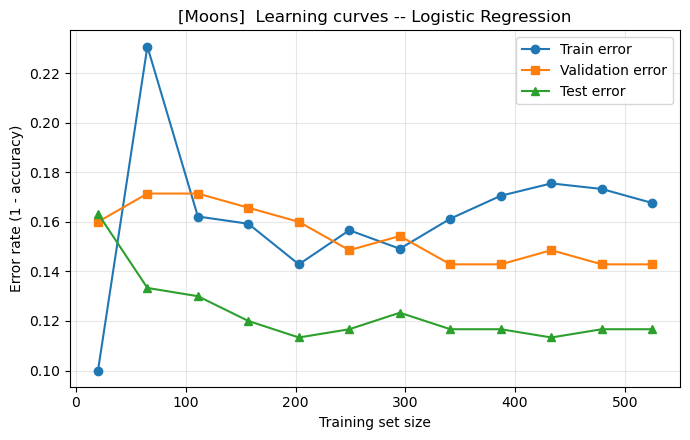

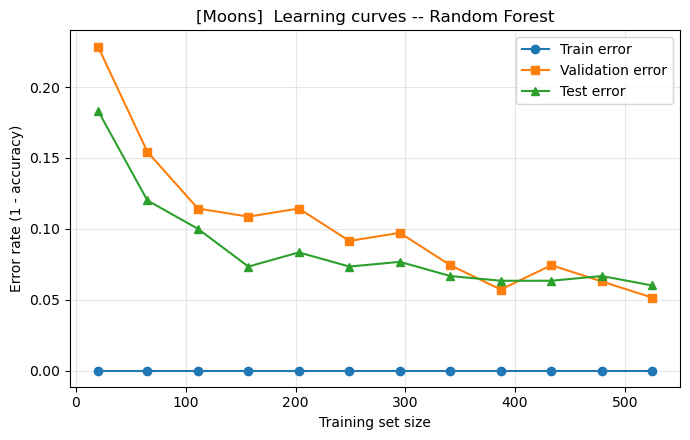

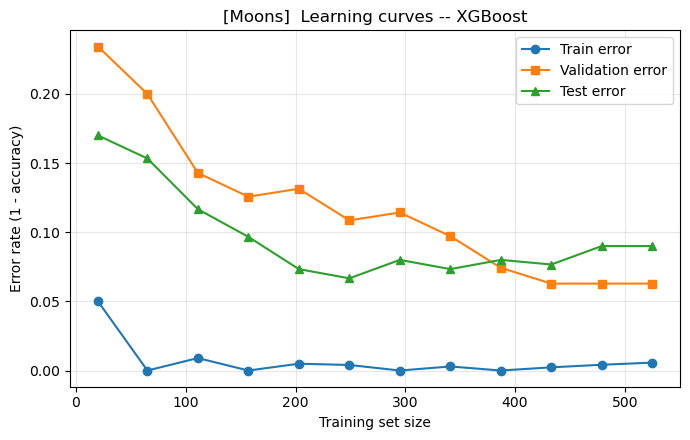

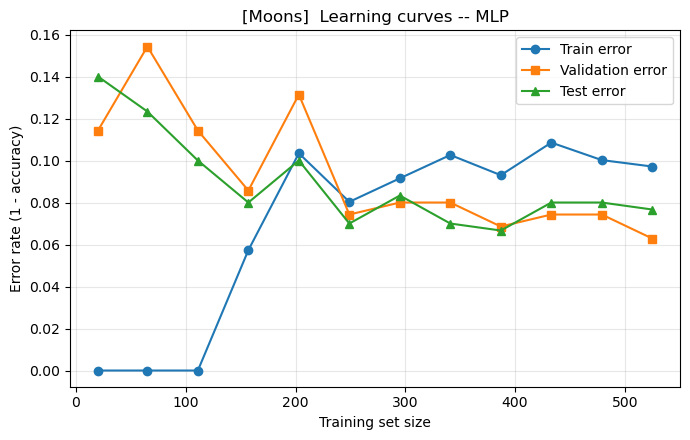

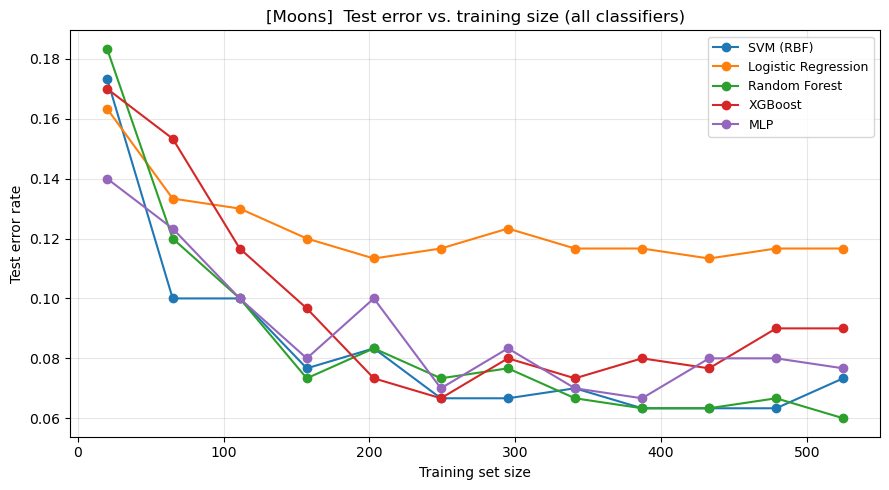

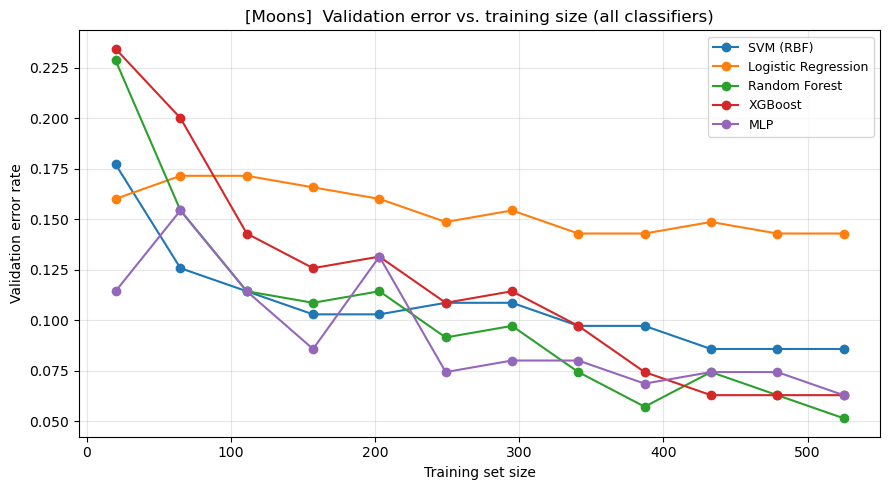

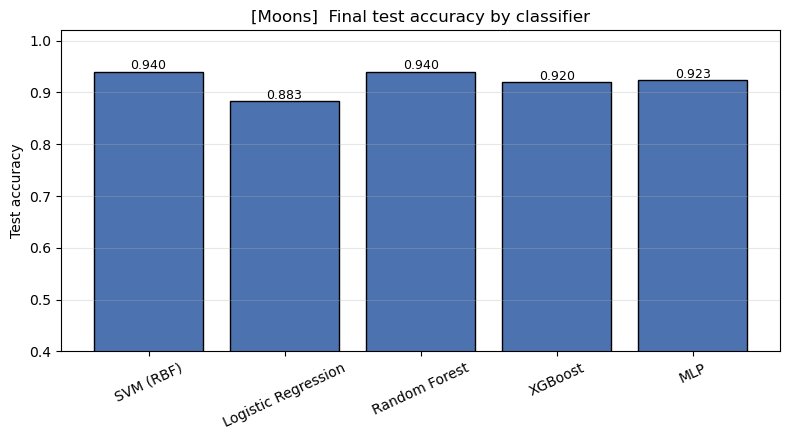

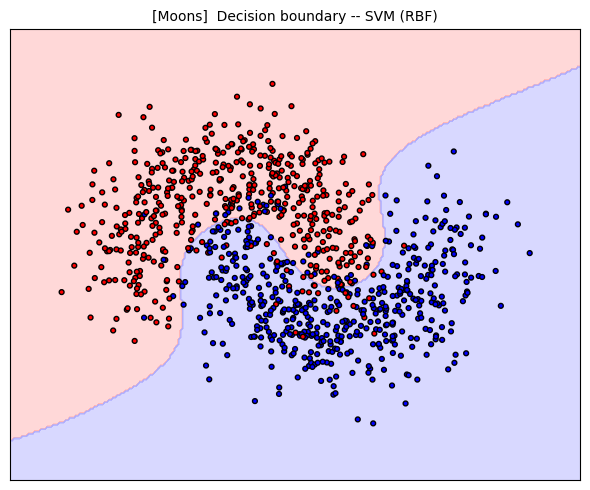

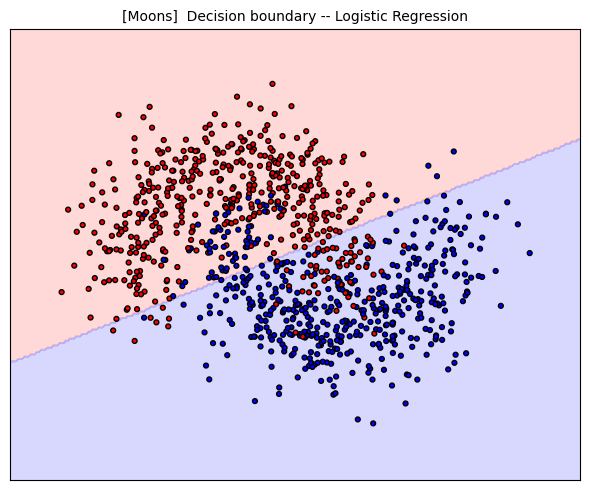

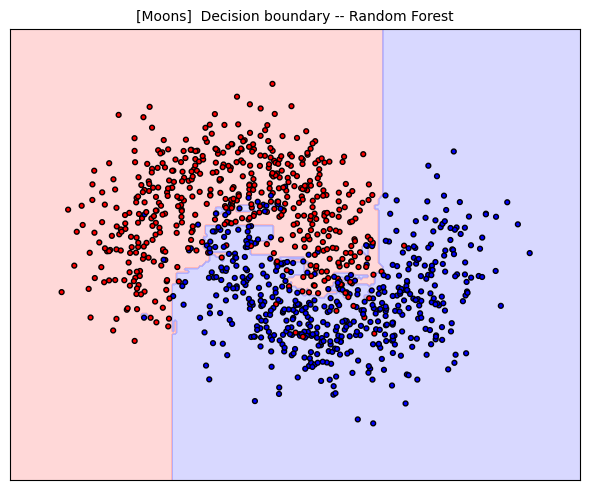

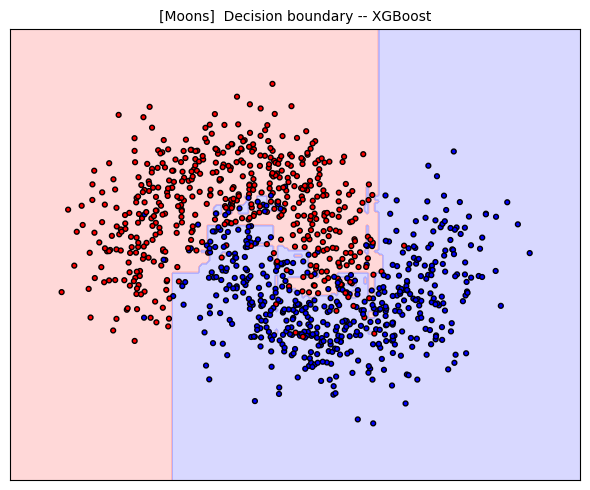

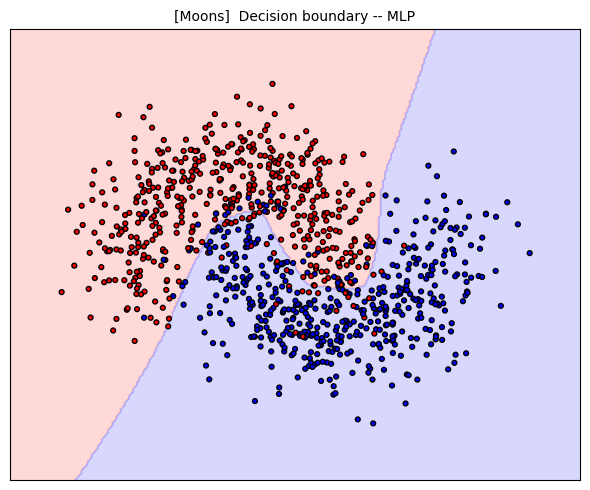

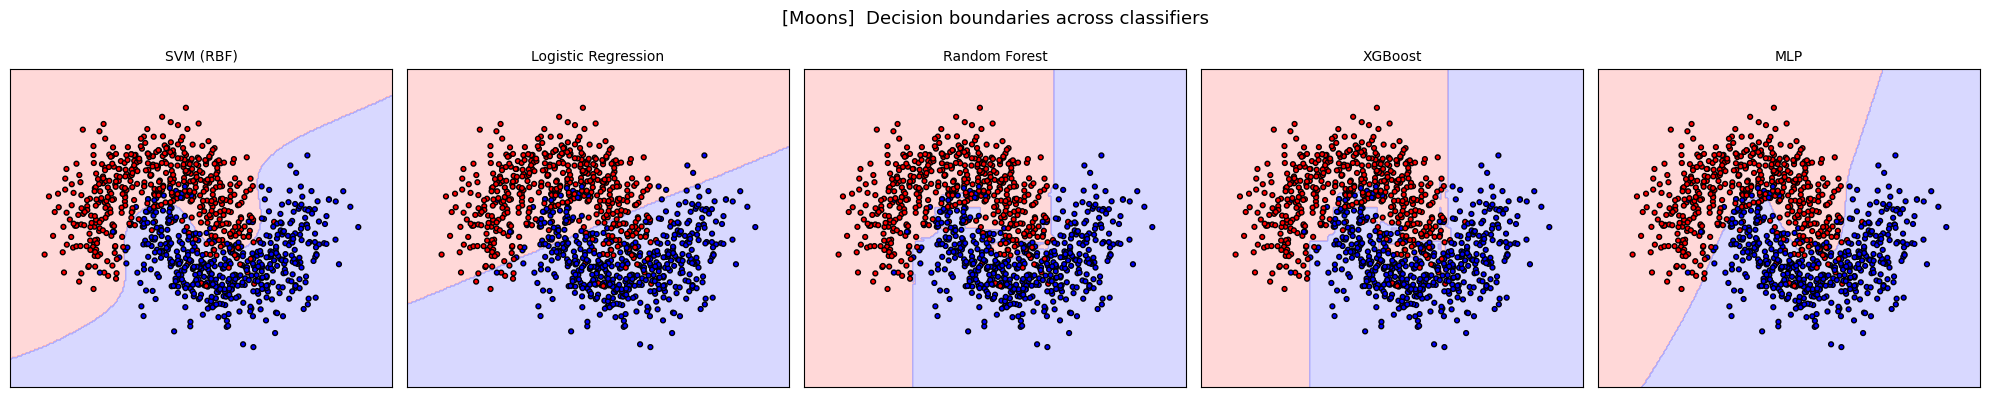


DATASET: Spirals   |   n = 1000, features = 2
  SVM (RBF)               ->  test accuracy = 0.9767
  Logistic Regression     ->  test accuracy = 0.5933
  Random Forest           ->  test accuracy = 0.9900
  XGBoost                 ->  test accuracy = 0.9900
  MLP                     ->  test accuracy = 0.9933


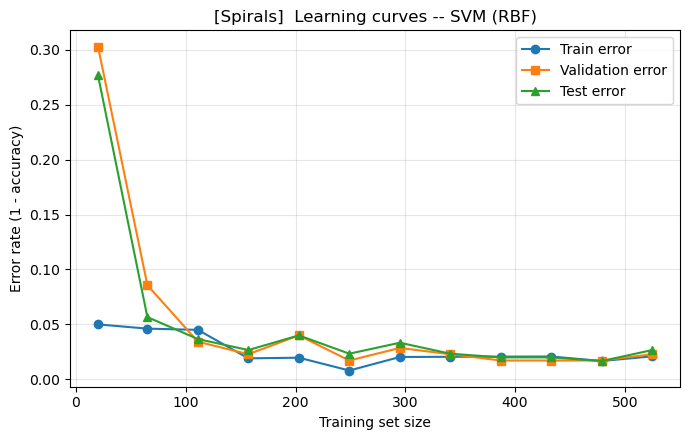

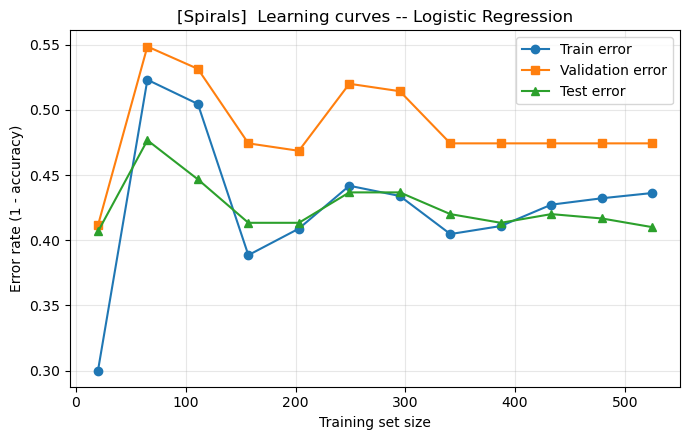

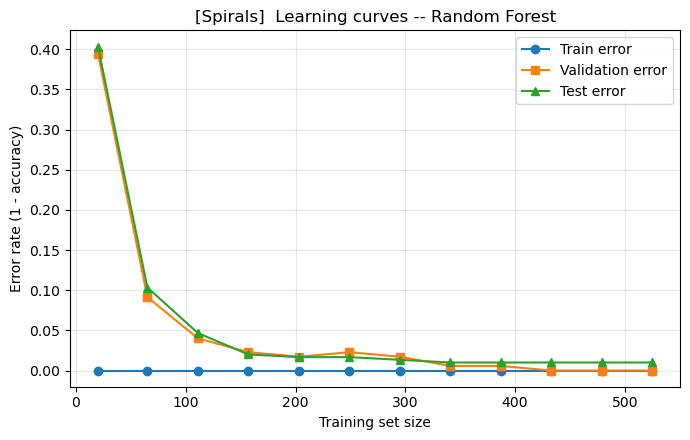

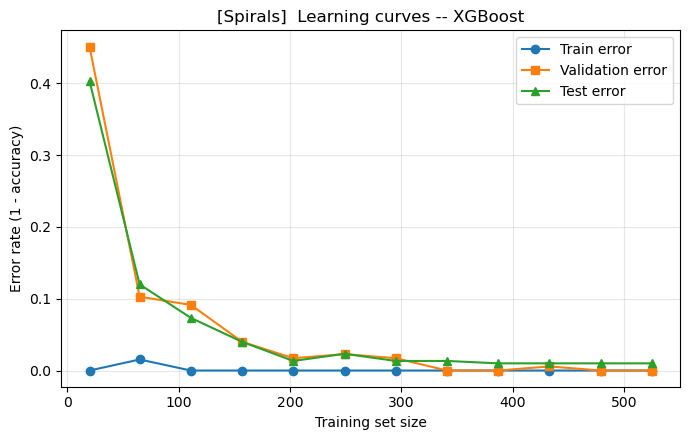

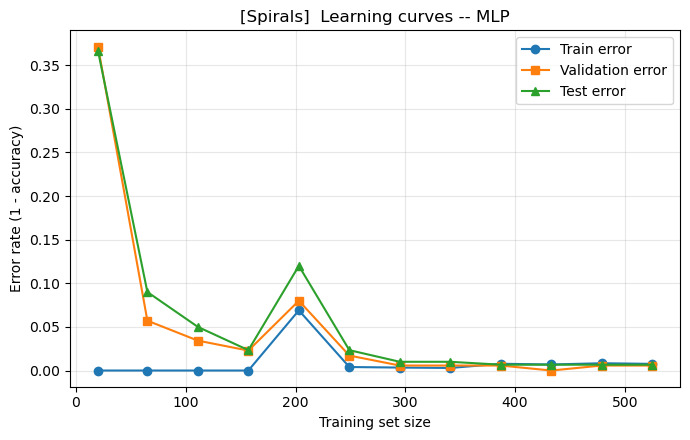

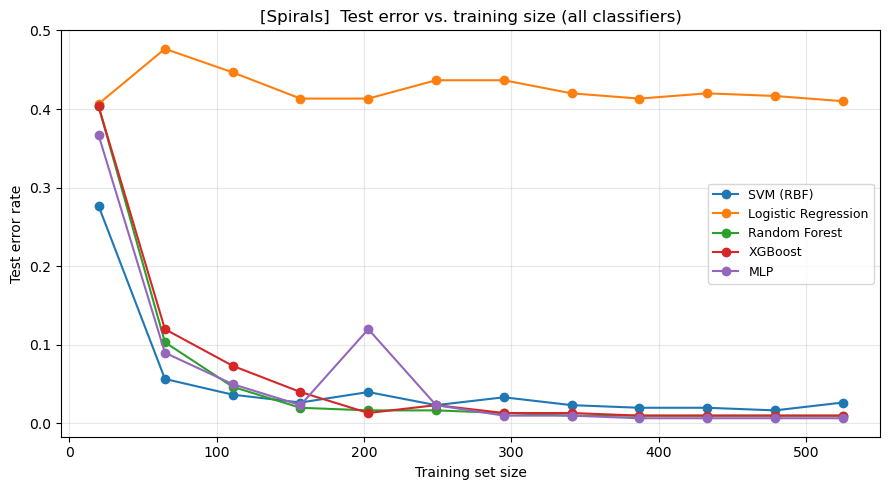

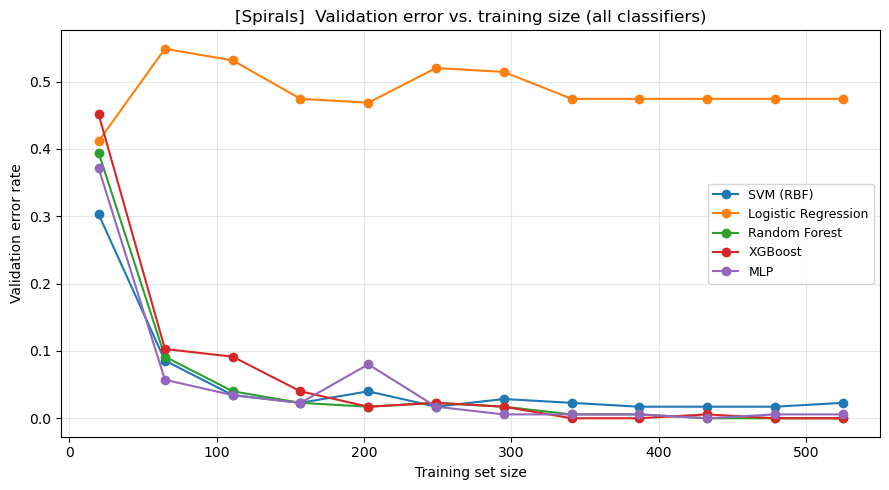

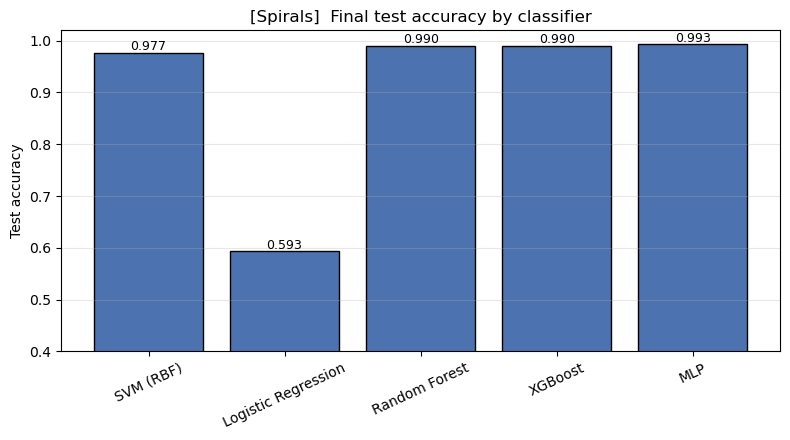

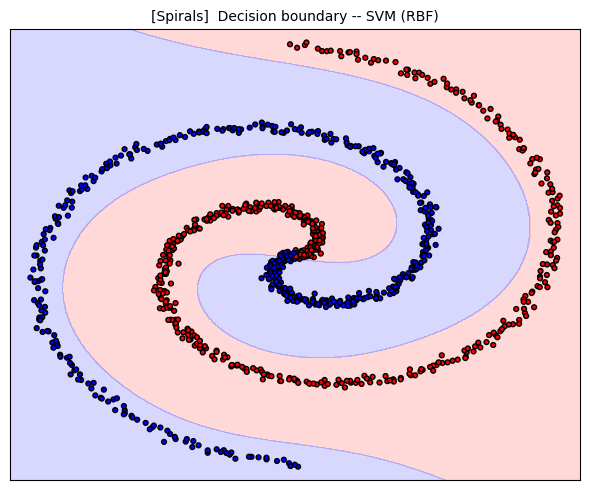

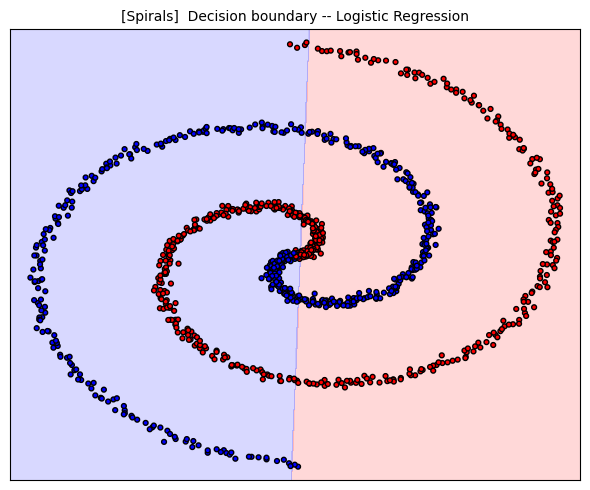

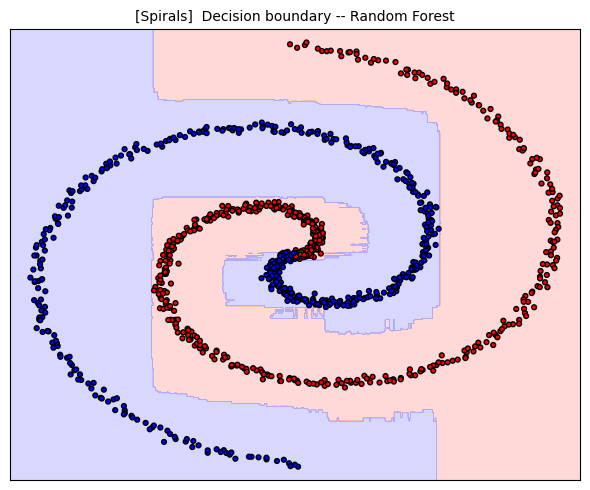

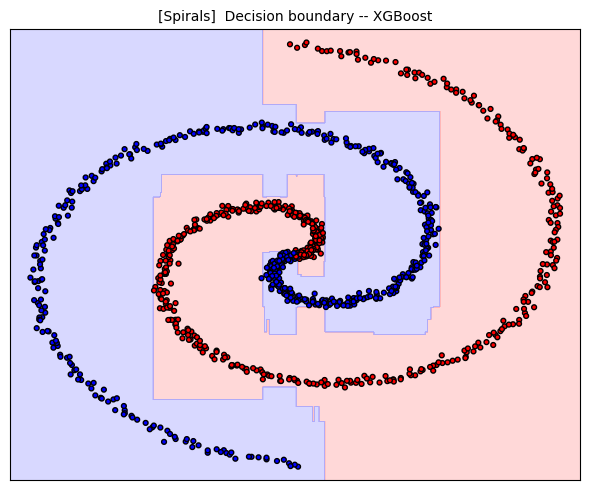

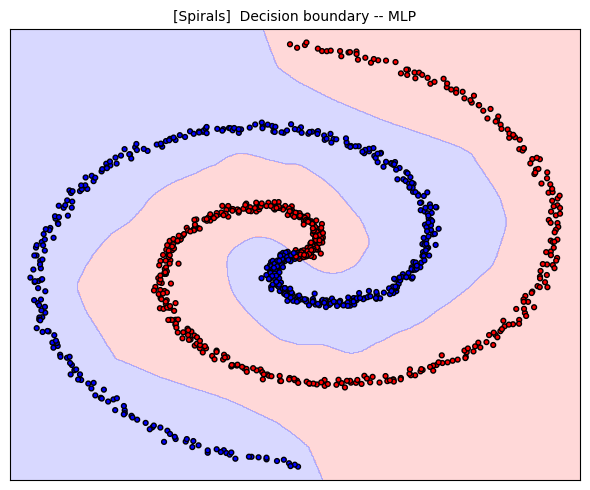

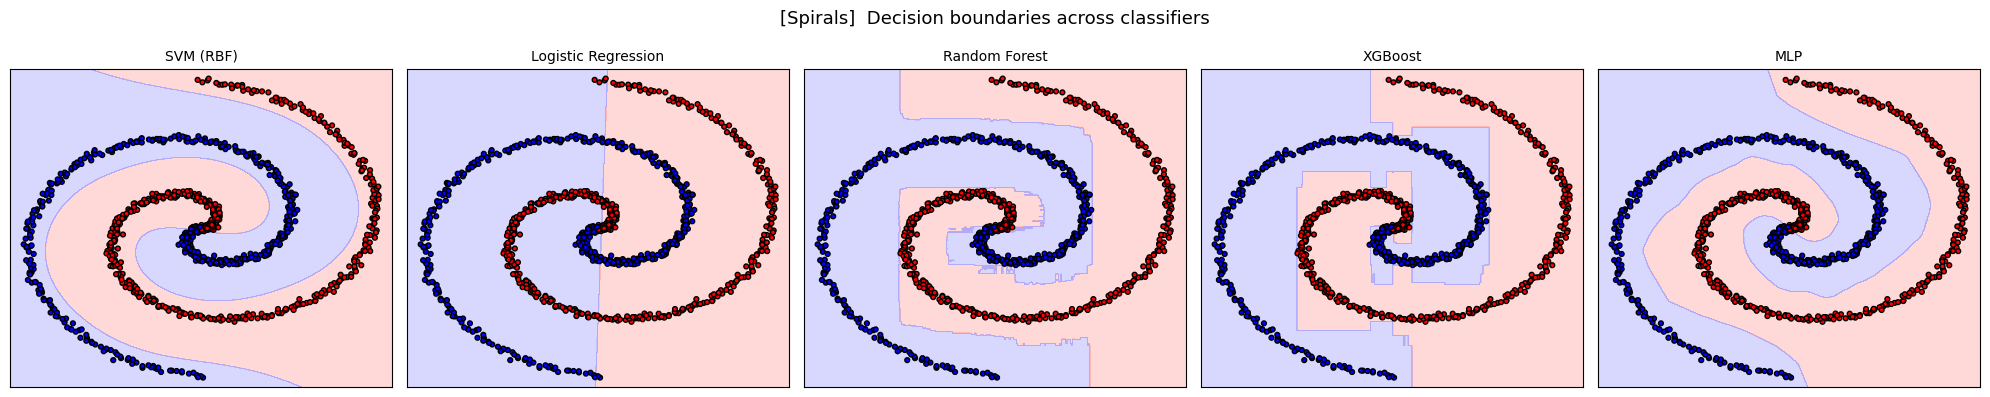

In [2]:
# =============================================================================
# Binary Classifier Comparison Toolkit -- Moons & Spirals
# =============================================================================
# Compares SVM, Logistic Regression, Random Forest, XGBoost, and MLP on:
#   (1) sklearn.datasets.make_moons  -- "approximately separable"
#   (2) a two-spirals dataset       -- strongly non-separable
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

RNG = np.random.RandomState(42)

# =============================================================================
# 1. Dataset generators
# =============================================================================
def load_moons(n_samples=1000, noise=0.30):
    """Two moons with enough noise to be 'approximately' separable."""
    X, y = make_moons(n_samples=n_samples, noise=noise, random_state=42)
    return X, y


def load_spirals(n_samples=1000, noise=0.10, n_turns=2.5):
    """
    Classic two-spirals dataset.
    Each class is an Archimedean spiral rotated 180 deg from the other.
    Non-separable by any linear or shallow model.
    """
    n = n_samples // 2
    t = np.linspace(0.0, n_turns * np.pi, n)

    # Spiral 1
    r1 = t
    x1 =  r1 * np.cos(t) + RNG.randn(n) * noise
    y1 =  r1 * np.sin(t) + RNG.randn(n) * noise

    # Spiral 2 (rotated by pi)
    r2 = t
    x2 = -r2 * np.cos(t) + RNG.randn(n) * noise
    y2 = -r2 * np.sin(t) + RNG.randn(n) * noise

    X = np.vstack([np.c_[x1, y1], np.c_[x2, y2]])
    y = np.hstack([np.zeros(n, dtype=int), np.ones(n, dtype=int)])

    # Shuffle
    idx = RNG.permutation(len(X))
    return X[idx], y[idx]


# =============================================================================
# 2. Classifier factory (fresh instances per dataset)
# =============================================================================
def build_classifiers():
    return {
        'SVM (RBF)': make_pipeline(
            StandardScaler(),
            SVC(kernel='rbf', C=10.0, gamma='scale', probability=False, random_state=42)
        ),
        'Logistic Regression': make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, random_state=42)
        ),
        'Random Forest': RandomForestClassifier(
            n_estimators=300, max_depth=None, random_state=42, n_jobs=-1
        ),
        'XGBoost': XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.1,
            use_label_encoder=False, eval_metric='logloss',
            random_state=42, n_jobs=-1
        ),
        'MLP': make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=2000,
                          random_state=42, early_stopping=False)
        ),
    }


# =============================================================================
# 3. Learning-curve computation
# =============================================================================
def compute_error_curves(clf, X_tr, y_tr, X_val, y_val, X_te, y_te,
                         n_points=12, min_size=20):
    n = len(X_tr)
    sizes = np.unique(np.linspace(min_size, n, n_points).astype(int))
    train_err, val_err, test_err = [], [], []
    for s in sizes:
        clf.fit(X_tr[:s], y_tr[:s])
        train_err.append(1 - accuracy_score(y_tr[:s], clf.predict(X_tr[:s])))
        val_err.append(1 - accuracy_score(y_val,   clf.predict(X_val)))
        test_err.append(1 - accuracy_score(y_te,   clf.predict(X_te)))
    return sizes, np.array(train_err), np.array(val_err), np.array(test_err)


# =============================================================================
# 4. Decision-boundary plotting
# =============================================================================
def plot_decision_boundary(clf, X, y, title, ax, h=0.02):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    cmap_bg = ListedColormap(['#FFAAAA', '#AAAAFF'])
    cmap_pt = ListedColormap(['#FF0000', '#0000FF'])
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.45)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_pt, edgecolor='k', s=12)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(()); ax.set_yticks(())


# =============================================================================
# 5. Main pipeline (runs for a single dataset)
# =============================================================================
def run_pipeline(dataset_name, X, y):
    print("\n" + "=" * 72)
    print(f"DATASET: {dataset_name}   |   n = {len(X)}, features = {X.shape[1]}")
    print("=" * 72)

    # --- 3-way split ---
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.25,
        random_state=42, stratify=y_train_full
    )

    classifiers = build_classifiers()
    results = {}

    # --- Fit + learning curves ---
    for name, clf in classifiers.items():
        sizes, tr, va, te = compute_error_curves(
            clf, X_train, y_train, X_val, y_val, X_test, y_test
        )
        results[name] = dict(sizes=sizes, train=tr, val=va, test=te)

        clf.fit(X_train_full, y_train_full)
        acc = accuracy_score(y_test, clf.predict(X_test))
        print(f"  {name:22s}  ->  test accuracy = {acc:.4f}")

    # --- Per-classifier learning curves ---
    for name, r in results.items():
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.plot(r['sizes'], r['train'], 'o-', label='Train error',      color='#1f77b4')
        ax.plot(r['sizes'], r['val'],   's-', label='Validation error', color='#ff7f0e')
        ax.plot(r['sizes'], r['test'],  '^-', label='Test error',       color='#2ca02c')
        ax.set_xlabel('Training set size')
        ax.set_ylabel('Error rate (1 - accuracy)')
        ax.set_title(f'[{dataset_name}]  Learning curves -- {name}')
        ax.legend(); ax.grid(alpha=0.3)
        plt.tight_layout(); plt.show()

    # --- Comparison: test-error curves ---
    fig, ax = plt.subplots(figsize=(9, 5))
    for name, r in results.items():
        ax.plot(r['sizes'], r['test'], 'o-', label=name)
    ax.set_xlabel('Training set size')
    ax.set_ylabel('Test error rate')
    ax.set_title(f'[{dataset_name}]  Test error vs. training size (all classifiers)')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Comparison: validation-error curves ---
    fig, ax = plt.subplots(figsize=(9, 5))
    for name, r in results.items():
        ax.plot(r['sizes'], r['val'], 'o-', label=name)
    ax.set_xlabel('Training set size')
    ax.set_ylabel('Validation error rate')
    ax.set_title(f'[{dataset_name}]  Validation error vs. training size (all classifiers)')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Bar chart of final test accuracy ---
    final_acc = {}
    for name, clf in classifiers.items():
        clf.fit(X_train_full, y_train_full)
        final_acc[name] = accuracy_score(y_test, clf.predict(X_test))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    names  = list(final_acc.keys())
    values = [final_acc[n] for n in names]
    bars = ax.bar(names, values, color='#4c72b0', edgecolor='black')
    for b, v in zip(bars, values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.005,
                f'{v:.3f}', ha='center', fontsize=9)
    ax.set_ylim(0.4, 1.02)
    ax.set_ylabel('Test accuracy')
    ax.set_title(f'[{dataset_name}]  Final test accuracy by classifier')
    ax.tick_params(axis='x', rotation=25); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout(); plt.show()

    # --- Individual decision boundaries ---
    for name, clf in classifiers.items():
        clf.fit(X_train_full, y_train_full)
        fig, ax = plt.subplots(figsize=(6, 5))
        plot_decision_boundary(clf, X, y, f'[{dataset_name}]  Decision boundary -- {name}', ax)
        plt.tight_layout(); plt.show()

    # --- Combined boundary panel ---
    fig, axes = plt.subplots(1, len(classifiers),
                             figsize=(4 * len(classifiers), 4))
    for ax, (name, clf) in zip(axes, classifiers.items()):
        clf.fit(X_train_full, y_train_full)
        plot_decision_boundary(clf, X, y, name, ax)
    fig.suptitle(f'[{dataset_name}]  Decision boundaries across classifiers',
                 fontsize=13)
    plt.tight_layout(); plt.show()


# =============================================================================
# 6. Run both datasets
# =============================================================================
X_moons, y_moons     = load_moons(n_samples=1000, noise=0.30)
X_spirals, y_spirals = load_spirals(n_samples=1000, noise=0.10, n_turns=2.5)

run_pipeline("Moons",   X_moons,   y_moons)
run_pipeline("Spirals", X_spirals, y_spirals)